# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [1]:
# YOUR CODE HERE
import glob
from datasets import load_dataset

# Checking .md files
md_files = glob.glob("Dataset/Dataset/sop_documents/*.md")
print("Policy files found:", md_files)

# Load bitext dataset
dataset = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")
df = dataset["train"].to_pandas()
df.info()

/home/piyush0912/pyspark-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Policy files found: ['Dataset/Dataset/sop_documents/working_hours.md', 'Dataset/Dataset/sop_documents/order_tracking.md', 'Dataset/Dataset/sop_documents/billing_disputes.md', 'Dataset/Dataset/sop_documents/product_return.md', 'Dataset/Dataset/sop_documents/password_reset.md', 'Dataset/Dataset/sop_documents/data_privacy.md', 'Dataset/Dataset/sop_documents/technical_troubleshooting.md', 'Dataset/Dataset/sop_documents/subscription_cancellation.md', 'Dataset/Dataset/sop_documents/refund_policy.md', 'Dataset/Dataset/sop_documents/shipping_delays.md', 'Dataset/Dataset/sop_documents/account_recovery.md', 'Dataset/Dataset/sop_documents/payment_methods.md', 'Dataset/Dataset/sop_documents/escalation_matrix.md']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [2]:
# YOUR CODE HERE
print(len(df))
print(df['intent'].nunique())

26872
27


In [3]:
sample = df.sample(4000, random_state=42)
sample = sample.reset_index()
sample.head()

,index,flags,instruction,category,intent,response
0,9329,BLZ,I can't talk with a human agent,CONTACT,contact_human_agent,Thank you for reaching out! I'm sorry to hear ...
1,4160,BLMZ,I have got to locate hte bills from {{Person N...,INVOICE,check_invoice,I'll get right on it! I understand your need t...
2,18500,BCELM,"I cannot pay, help me to inform of a problem w...",PAYMENT,payment_issue,I apologize for the inconvenience caused by th...
3,8840,BL,I want help speaking to customer service,CONTACT,contact_customer_service,Grateful for your contact! I get the sense tha...
4,5098,BLZ,I try to see th accepted payment options,PAYMENT,check_payment_methods,Thank you for reaching out! I completely under...


In [4]:
from transformers import AutoTokenizer
import pandas as pd

tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")

print(f"Full dataset: {len(df)} rows | Sample: {len(sample)} rows (within 1,000-5,000) | Intents: {sample['intent'].nunique()}")

lengths = pd.DataFrame({
    "char_len":  sample['instruction'].str.len(),
    "word_len":  sample['instruction'].str.split().str.len(),
    "token_len": sample['instruction'].apply(lambda t: len(tok(t)['input_ids'])),
})
print(lengths.describe().round(1))
print("95th percentile (tokens):", int(lengths['token_len'].quantile(0.95)))

Full dataset: 26872 rows | Sample: 4000 rows (within 1,000-5,000) | Intents: 27
       char_len  word_len  token_len
count    4000.0    4000.0     4000.0
mean       46.9       8.8       10.2
std        10.7       2.6        3.1
min         8.0       1.0        1.0
25%        40.0       7.0        8.0
50%        48.0       9.0       10.0
75%        55.0      11.0       12.0
max        92.0      16.0       21.0
95th percentile (tokens): 15


In [11]:
sample['category'].value_counts()

category
ACCOUNT         860
ORDER           551
REFUND          450
FEEDBACK        319
INVOICE         315
PAYMENT         314
CONTACT         313
SHIPPING        313
DELIVERY        308
CANCEL          142
SUBSCRIPTION    115
Name: count, dtype: int64

#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [5]:
# YOUR CODE HERE
print(sample.isnull().sum())

index          0
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [6]:
sample['instruction'] = sample['instruction'].str.lower()
sample['instruction'] = sample['instruction'].str.strip()

In [7]:
# Incomplete records
print("Null values per column:\n", sample.isnull().sum(), "\n")
print("Empty instructions:", (sample['instruction'].str.strip() == '').sum())

# Formatting inconsistencies
print("Double spaces in instruction:", sample['instruction'].str.contains(r'\s{2,}', regex=True).sum())
print("Template placeholders ({{...}}):", sample['instruction'].str.contains(r'\{\{.*?\}\}', regex=True).sum())
print("intent not lowercase:", (sample['intent'] != sample['intent'].str.lower()).sum(),
      "| category not uppercase:", (sample['category'] != sample['category'].str.upper()).sum())

# Duplicates and near-duplicates (checked on the raw text, before lowercasing)
raw = df.loc[sample['index'], 'instruction'].reset_index(drop=True)
exact_dups = raw.duplicated().sum()
norm_dups  = raw.str.lower().str.strip().duplicated().sum()
print(f"\nExact duplicates: {exact_dups} | Near-duplicates (lowercase + strip): {norm_dups - exact_dups}")

# Prompt-solution alignment
intent_cat = sample.groupby('intent')['category'].nunique()
print("Intents mapped to more than one category:", (intent_cat > 1).sum())
vc = sample['intent'].value_counts()
print(f"Class imbalance (max/min intent count): {vc.max()} / {vc.min()} = {vc.max()/vc.min():.1f}x")

Null values per column:
 index          0
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64 

Empty instructions: 0
Double spaces in instruction: 79
Template placeholders ({{...}}): 938
intent not lowercase: 0 | category not uppercase: 0

Exact duplicates: 83 | Near-duplicates (lowercase + strip): 15
Intents mapped to more than one category: 0
Class imbalance (max/min intent count): 169 / 115 = 1.5x


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

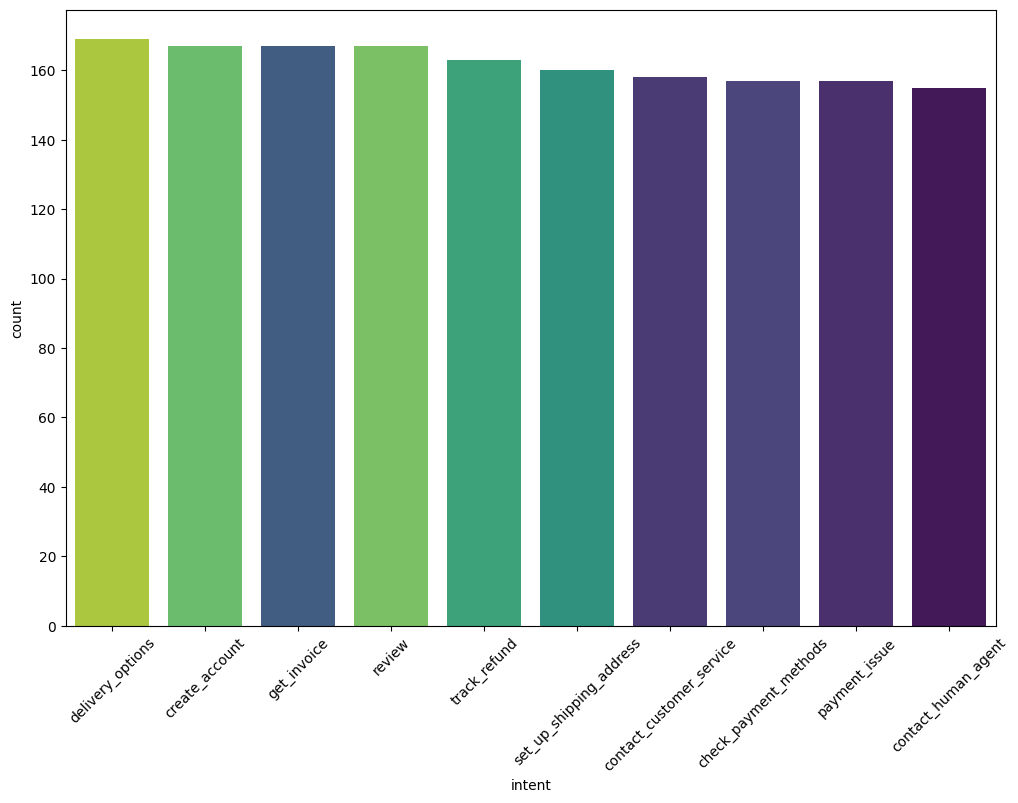

In [8]:
# YOUR CODE HERE
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
sns.countplot(data=sample,x='intent', order=sample['intent'].value_counts().index[:10], palette='viridis', hue='intent')
plt.xticks(rotation=45)
plt.show()

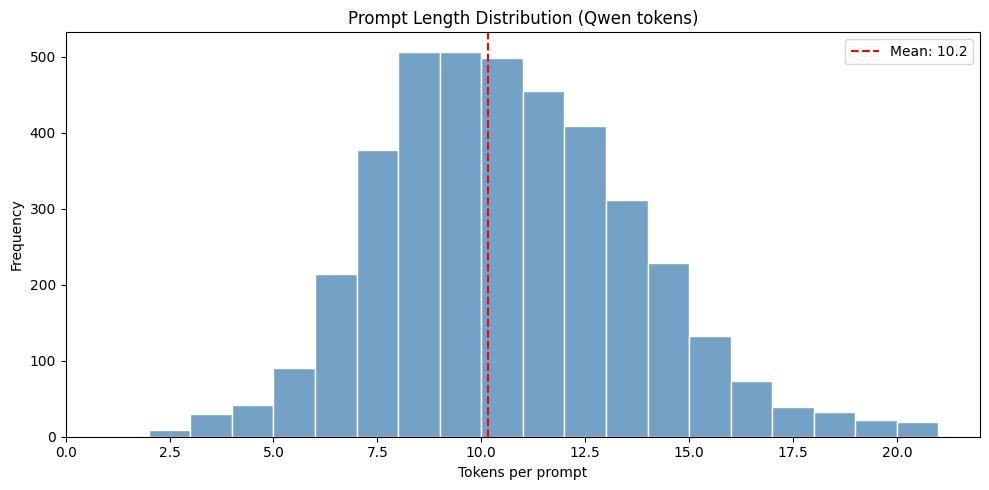

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(lengths['token_len'], bins=20, color='steelblue', edgecolor='white')
plt.axvline(lengths['token_len'].mean(), color='red', linestyle='--', label=f"Mean: {lengths['token_len'].mean():.1f}")
plt.title('Prompt Length Distribution (Qwen tokens)')
plt.xlabel('Tokens per prompt')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [10]:
# YOUR CODE HERE
md_data = []

for filename in glob.glob("Dataset/Dataset/sop_documents/*.md"):
    with open(filename, "r") as file:
        md_data.append({
            "filename": filename,
            "content": file.read()
        })

print(f"Loaded {len(md_data)} policy documents")

Loaded 13 policy documents


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform([doc['content'] for doc in md_data])

print(X.shape)

(13, 797)


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

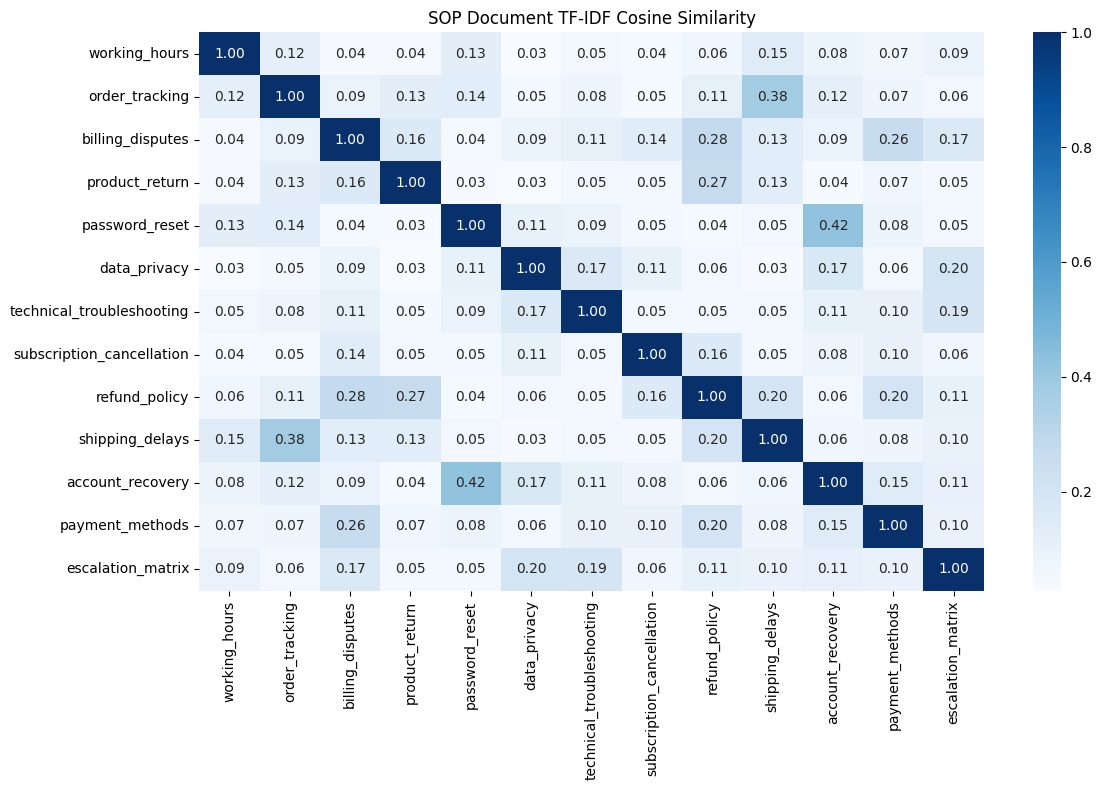

In [12]:
# YOUR CODE HERE
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

similarity_matrix = cosine_similarity(X)

# get just filenames for labels
labels = [doc['filename'].split('/')[-1].replace('.md','') for doc in md_data]

plt.figure(figsize=(12, 8))
sns.heatmap(similarity_matrix, 
            xticklabels=labels, 
            yticklabels=labels, 
            annot=True, 
            fmt='.2f',
            cmap='Blues')
plt.title('SOP Document TF-IDF Cosine Similarity')
plt.tight_layout()
plt.show()

In [13]:
import itertools

pairs = [(labels[i], labels[j], similarity_matrix[i, j])
         for i, j in itertools.combinations(range(len(labels)), 2)]
print("Most similar SOP pairs (candidates for overlapping or conflicting rules):")
for a, b, s in sorted(pairs, key=lambda x: -x[2])[:5]:
    print(f"{a:28} vs {b:28} {s:.2f}")

Most similar SOP pairs (candidates for overlapping or conflicting rules):
password_reset               vs account_recovery             0.42
order_tracking               vs shipping_delays              0.38
billing_disputes             vs refund_policy                0.28
product_return               vs refund_policy                0.27
billing_disputes             vs payment_methods              0.26


---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [45]:
# YOUR CODE HERE
import os

# create artifacts folder if it doesn't exist
os.makedirs("artifacts", exist_ok=True)

# save the sampled and cleaned dataframe
sample.to_csv("artifacts/sampled_dataset.csv", index=False)

print(f"Saved {len(sample)} rows to artifacts/cleaned_dataset.csv")

Saved 4000 rows to artifacts/cleaned_dataset.csv


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**